# Sports Vision: training en resultaten
Uitgevoerd inspectienotebook bij de documentatiesnapshot van **15 november 2026**.
Dit notebook toont de echte meegeleverde trainingslogs, datasetindeling, gewichten en ontwikkelmetrics.
Het reconstrueert geen nieuwe historische training. De modelruns zijn eerder uitgevoerd.
Versie 4 na pull naar 524d081a. De menselijke teamreview van alle 80 beelden is op 14 november geregistreerd.
De nieuwste handleiding meldt behoud van YOLO11s na de YOLO26-proef. Nieuwe cijfers zijn
bronrapportages zolang de ruwe lokale experimentmappen ontbreken.

Benodigd voor inspectie: Python 3.11 of 3.12, pandas, matplotlib, PyYAML en een Jupyter-kernel.
Alle inspectiecellen lezen lokale bestanden. De laatste trainingscel staat expliciet uit. Dit notebook publiceert geen nieuwe trainingsresultaten.

Aanvulling versie 5: de koppeling van alle 80 reviewbeelden met de historische baltraining is inmiddels op hashes, splits en 174 positieve croptransformaties aangetoond. Zie Koppeling_80_Beelden_en_Baltraining.md en het uitgevoerde notebook ../Upload_CV_Challenge_2026_11_14/03_Code/Bal_v2_Training_en_Labelkoppeling.ipynb. De bestaande inspectie-uitvoer hieronder blijft die van de vorige documentatieronde.


In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Markdown, Image

here = Path.cwd().resolve()
possibilities = [here, here / 'Documentatie', here.parent / 'Documentatie']
DOC = next(p for p in possibilities if (p / 'Rapport_Sports_Vision.md').is_file())
base = DOC.parent
FINAL = next(p for p in [base / 'final', base / 'Messi10' / 'final'] if (p/'streamlit_app.py').is_file())
def read(p): return json.loads(Path(p).read_text(encoding='utf-8-sig'))
def checksum(p):
    with Path(p).open('rb') as f: return hashlib.file_digest(f, 'sha256').hexdigest()
print('Documentatie:', DOC)
print('Applicatie:', FINAL)
SOURCE = next(p for p in [base,base/'Messi10',base/'Nieuwste_bron'] if (p/'configs/models-broadcast.json').is_file())
print('Hoofdbron:',SOURCE)
print('Status: ontwikkelmetingen; 80 labels goedgekeurd volgens teamverklaring; geen onafhankelijke eindtest.')

Documentatie: C:\Allerlaatste\DeepLearning\CV\Messi10\Documentatie
Applicatie: C:\Allerlaatste\DeepLearning\CV\Messi10\final
Hoofdbron: C:\Allerlaatste\DeepLearning\CV\Messi10
Status: ontwikkelmetingen; 80 labels goedgekeurd volgens teamverklaring; geen onafhankelijke eindtest.


## 1. Dataset en annotatie
De meegeleverde onderwijsselectie telt 80 beelden. Zij is een aparte reviewselectie uit bestaande
ontwikkeldata, met **48 train / 32 validatie** en gescheiden wedstrijden. De latere v2/v3-training
gebruikt 282 crops uit 132 bronbeelden. Die datasets zijn niet onderling uitwisselbaar.
Alle huidige 80 labels zijn volgens de geregistreerde teamverklaring goedgekeurd.
De labelbestanden en de 48/32-split zijn ongewijzigd. De oorspronkelijke AI/provider-herkomst blijft vermeld.
Deze registratie keurt andere historische datasets niet automatisch goed.

In [2]:
dataset = FINAL / 'datasets/school-ball80-review-v1'
manifest = read(dataset/'manifest.json')
frames = pd.DataFrame(manifest['frames'])
display(frames.groupby(['split','group_id']).size().rename('beelden').to_frame())
assert len(frames) == 80
assert frames['split'].value_counts().to_dict() == {'train':48,'val':32}
assert not (set(frames.loc[frames.split=='train','group_id']) & set(frames.loc[frames.split=='val','group_id']))
for row in manifest['frames']:
    for kind in ['image','label']:
        assert checksum(dataset/row[kind]) == row[f'initial_{kind}_sha256']
print('80 beeld-labelparen en hashes gecontroleerd; geen overlap tussen wedstrijdgroepen.')
print('Menselijke review voltooid:', manifest['human_review_completed'])
assert manifest['human_review_completed'] is True
assert all(row['review_status']=='approved' for row in manifest['frames'])
print('Registratie:',manifest['human_review_record'])
display(frames[['frame_id','split','annotator','reviewer','review_status']].head())

beelden
15
15
18
10
11
11


frame_id,split,annotator,reviewer,review_status
SNGS-060_000486,train,Codex (AI),Projectteam (bevestigd door gebruiker),approved
SNGS-061_000241,train,Codex (AI),Projectteam (bevestigd door gebruiker),approved
SNGS-062_000496,train,Codex (AI),Projectteam (bevestigd door gebruiker),approved
SNGS-066_000506,train,Codex (AI),Projectteam (bevestigd door gebruiker),approved
SNGS-067_000271,train,Codex (AI),Projectteam (bevestigd door gebruiker),approved


80 beeld-labelparen en hashes gecontroleerd; geen overlap tussen wedstrijdgroepen.
Menselijke review voltooid: True
Registratie: {'recorded_at': '2026-11-14T19:07:42.558333+00:00', 'basis': 'explicit user confirmation', 'reviewer': 'Projectteam (bevestigd door gebruiker)', 'scope': 'All current 80 frames: 48 train, 32 val', 'decision': 'All current labels accepted; ambiguous candidates were outside this selection', 'label_files_changed_in_this_update': False, 'review_report': 'REVIEW.md', 'previous_manifest_sha256': '583850d240da788d1fe4d7bc89ac52fbdf497b524cab46a51ce5da2156f82c73'}


## 2. Wat de huidige app laadt
De nieuwste hoofdbron gebruikt YOLO11s-spelers, persoons-/rol-/teammodellen en uitsluitend de
baluitvoer uit Andrews YOLOv8x-vierklassencheckpoint. Het GitHub-final-pakket heeft een eigen
schoolroute. Lokale niet-gepubliceerde uitbreidingen worden niet als GitHub-functionaliteit voorgesteld.
Een SHA-256 bevestigt de identiteit van het bestand, niet de juistheid van voorspellingen.

In [3]:
profile=read(SOURCE/'configs/models-broadcast.json')
rows=[]
for model in profile['models']:
    p=(SOURCE/'configs'/model['weights']).resolve()
    actual=checksum(p)
    assert actual == model['weights_sha256']
    rows.append({'model':model['model_id'],'invoer':model['imgsz'],'confidence':model['confidence'],'NMS-IoU':model['iou'],'SHA256':actual})
display(pd.DataFrame(rows))
display(pd.DataFrame([{'onderdeel':key,'model':profile[key]['model_id']} for key in ['appearance','kit_embedding','role_context']]))

model,invoer,confidence,NMS-IoU,SHA256
broadcast-pitch-players-v7,1920,0.10,0.7,fb6deea2d6c51bada9d3f8bfd666882212f45d1a1584547d02dc98aa59aaaa25
coco-person-proposals,1920,0.10,0.5,d5ffc1a674953a08e11a8d21e022781b1b23a19b730afc309290bd9fb5305b95
andrew-ball-v1,1280,0.03,0.5,78a847ecd67f78566e666a54aabca6141e7e63495fb76783e17b3a859d90fee9


onderdeel,model
appearance,joint-selected-roles
kit_embedding,broadcast-kit-v1
role_context,pitch-role-context-observed-v8


## 3. Historische trainingsinstellingen en loss
De oorspronkelijke args.yaml en results.csv zijn als bewijs gekopieerd. Hun bron en checksum staan in
Trainingsbewijs/herkomst.json. v2 start van F005. v3 start van v2 en vergelijkt freeze 10 en freeze 0.
v2: maximaal 12 epochs, AdamW, batch 4, invoer 640, lr0 0.0001.
v3: maximaal 16 epochs, Adam, patience 8, batch 4, invoer 640, lr0 0.0001.
De multisource-spelerconfiguratie plant maximaal 40 epochs met early stopping. De CSV bepaalt hoeveel
epochs daadwerkelijk zijn gelogd. Een lossdaling bewijst geen verbetering op ongeziene wedstrijden.

In [4]:
logs={}
settings=[]
for name in ['bal-v2','bal-v3-freeze10','bal-v3-freeze0']:
    folder=DOC/'Trainingsbewijs'/name
    cfg=yaml.safe_load((folder/'args.yaml').read_text())
    table=pd.read_csv(folder/'results.csv')
    table.columns=table.columns.str.strip()
    logs[name]=table
    settings.append({'run':name,'gepland_epochs':cfg['epochs'],'gelogde_epochs':len(table),**{k:cfg.get(k) for k in ['imgsz','batch','optimizer','lr0','freeze','patience','seed']}})
cfg=yaml.safe_load((FINAL/'reports/broadcast-pitch-v1/multisource-training-20261028.yaml').read_text())
logs['spelers-multisource']=pd.read_csv(FINAL/'reports/broadcast-pitch-v1/multisource-training-20261028.csv')
settings.append({'run':'spelers-multisource','gepland_epochs':cfg['epochs'],'gelogde_epochs':len(logs['spelers-multisource']),**{k:cfg.get(k) for k in ['imgsz','batch','optimizer','lr0','freeze','patience','seed']}})
display(pd.DataFrame(settings))

run,gepland_epochs,gelogde_epochs,imgsz,batch,optimizer,lr0,freeze,patience,seed
bal-v2,12,12,640,4,AdamW,0.00010,10,12,42
bal-v3-freeze10,16,16,640,4,Adam,0.00010,10,8,42
bal-v3-freeze0,16,16,640,4,Adam,0.00010,0,8,42
spelers-multisource,40,11,1536,2,AdamW,0.00005,0,8,42


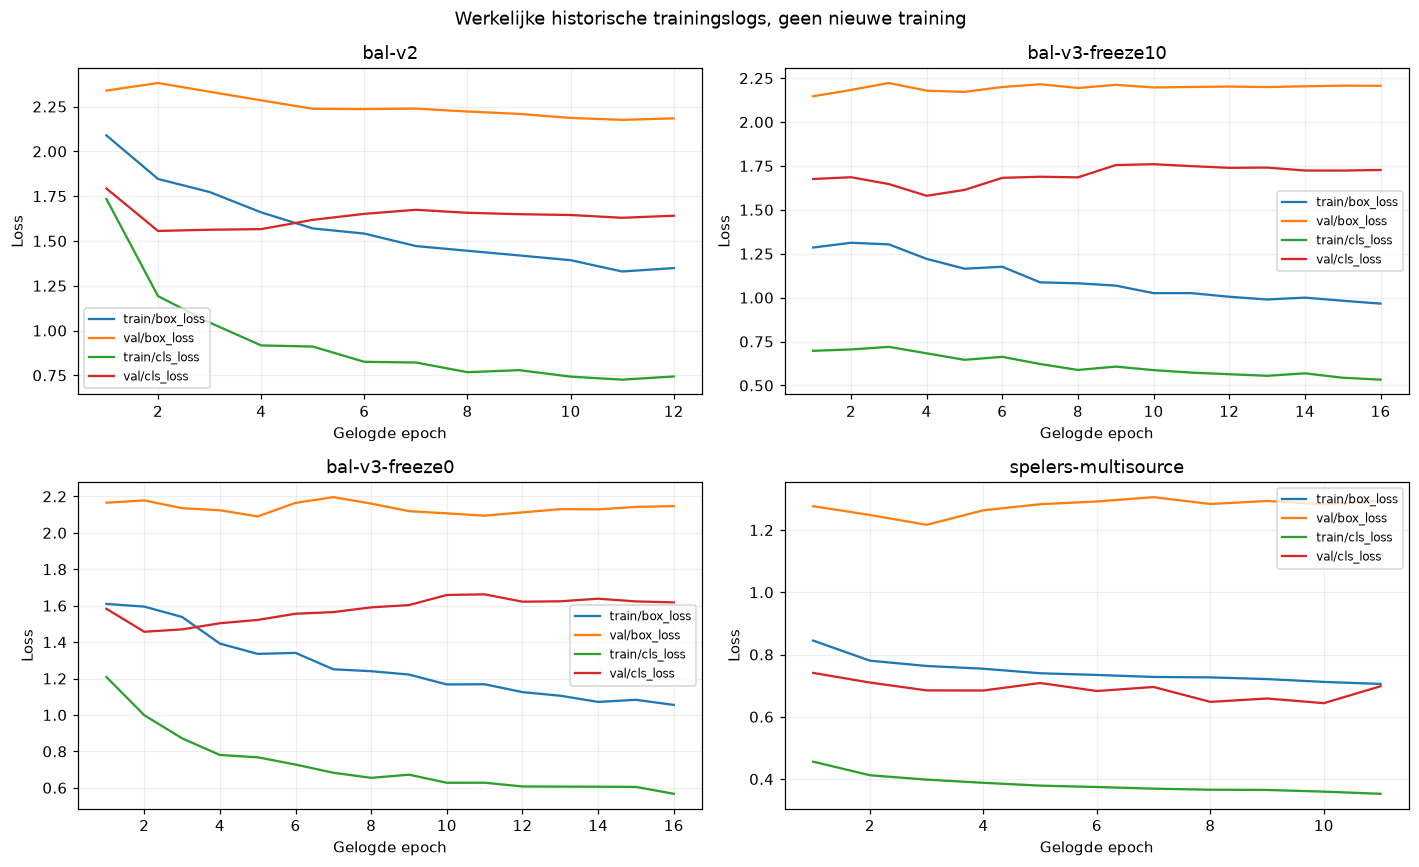

In [5]:
fig,axes=plt.subplots(2,2,figsize=(13,8))
for ax,(name,table) in zip(axes.flat,logs.items()):
    for col in ['train/box_loss','val/box_loss','train/cls_loss','val/cls_loss']:
        if col in table: ax.plot(table['epoch'],table[col],label=col)
    ax.set_title(name); ax.set_xlabel('Gelogde epoch'); ax.set_ylabel('Loss')
    ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.suptitle('Werkelijke historische trainingslogs, geen nieuwe training')
plt.tight_layout(); plt.show()

## 4. Eerlijke vergelijking van de balmodellen
AP gebruikt confidencevloer 0.001, de tellingen confidence 0.25 en matching-IoU 0.50.
De projectevaluator gebruikt 101-punts box-AP zonder volledige COCO-crowd/ignorebehandeling.
Alle onderstaande volledige-beelden- en tegelmetingen gebruiken dezelfde 73 ontwikkelbeelden.
De scores van native crops horen bij een andere inferentieroute en worden hier niet gemengd.

In [6]:
v2=read(FINAL/'reports/broadcast-data/v2-experiment.json')
v3=read(FINAL/'reports/broadcast-data/v3-experiment.json')
chosen=v3['selected_candidate']
measurements=[('F005 volledig 1280',v2['baseline']['full']),('v2 volledig 1280',v2['candidate']['full']),('F005 tegels',v2['baseline']['tiled']),('v2 tegels',v2['candidate']['tiled']),('v3 tegels',v3['candidates'][chosen]['measurements']['tiled']),('v3 volledig 1280',v3['candidates'][chosen]['measurements']['full'])]
rows=[]
for name,m in measurements:
    c=m['per_class'][0]
    rows.append({'modelroute':name,'beelden':m['frames'],'AP50_%':100*m['mAP50'],'AP50_95_%':100*m['mAP50_95'],**{k:c[k] for k in ['TP','FP','FN']}})
ball_results=pd.DataFrame(rows)
display(ball_results.round(2))
assert chosen=='freeze-0'
assert checksum(FINAL/'artifacts/broadcast-ball-v3/broadcast_ball_v3.pt')==v3['candidates'][chosen]['weights_sha256']
print('Geselecteerde v3:',chosen)
print('v3 verbetert de tegelroute, maar is zonder tegels zwakker dan v2.')

modelroute,beelden,AP50_%,AP50_95_%,TP,FP,FN
F005 volledig 1280,73,32.62,10.95,28,33,45
v2 volledig 1280,73,41.64,18.01,22,10,51
F005 tegels,73,27.38,10.19,23,33,50
v2 tegels,73,57.49,23.34,36,12,37
v3 tegels,73,63.57,25.74,36,5,37
v3 volledig 1280,73,38.47,16.79,19,10,54


Geselecteerde v3: freeze-0
v3 verbetert de tegelroute, maar is zonder tegels zwakker dan v2.


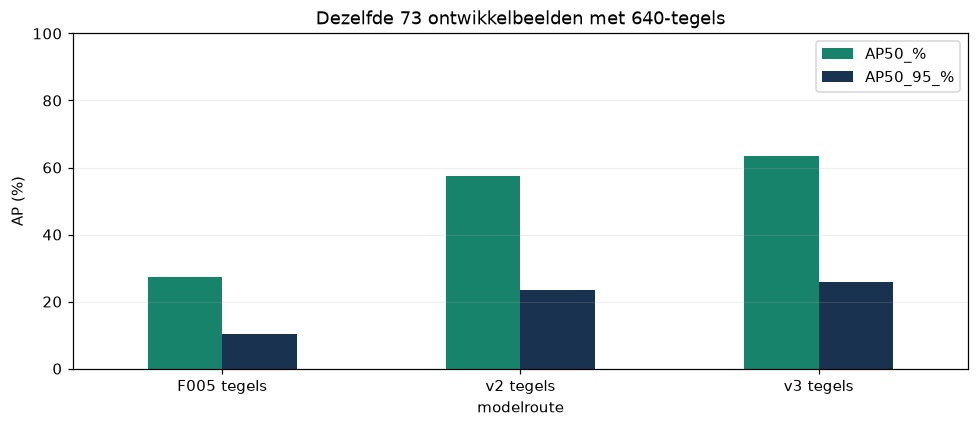

In [7]:
ax=ball_results.iloc[[2,3,4]].plot.bar(x='modelroute',y=['AP50_%','AP50_95_%'],color=['#16836a','#18324f'],figsize=(9,4),rot=0)
ax.set_ylabel('AP (%)'); ax.set_title('Dezelfde 73 ontwikkelbeelden met 640-tegels')
ax.set_ylim(0,100); ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.show()

## 5. Spelers en teams, conditionele evaluatie
Het geselecteerde broadcastmodel gebruikt **341 evalueerbare frames** met providergeometrie.
Deze evaluatie meet de automatische veldnauwkeurigheid niet. Het hoge aandeel correcte teamlabels
onder toegewezen gematchte spelers omvat gemiste spelers niet. Keeperteams blijven een zwak punt.

In [8]:
summary=read(FINAL/'reports/broadcast-pitch-v1/summary.json')
c=summary['candidates'][summary['selected']]
metrics=c['player_detection_and_roles']; t=c['teams']
display(pd.DataFrame([{'kandidaat':summary['selected'],'frames':c['frames'],'AP50_%':100*metrics['mAP50'],'AP50_95_%':100*metrics['mAP50_95'],'geometrie':summary['geometry_kind']}]))
display(pd.DataFrame([{k:t[k] for k in ['matched_players','correct','wrong','unknown','missed_players','false_positive_players','goalkeepers_total','goalkeepers_matched','goalkeepers_correct_team']}]))
print('Teamjuistheid toegewezen gematchte spelers:',round(100*t['accuracy_assigned'],2),'%')
print('Correct team over alle spelerreferenties:',round(100*t['correct_fraction_all_players'],2),'%')
print('Targets gehaald:',summary['targets_met'],'Menselijke review:',summary['human_review_completed'])

kandidaat,frames,AP50_%,AP50_95_%,geometrie
multisource-m,341,89.127473,53.829751,conditional provider object correspondences; not automatic-field accuracy


matched_players,correct,wrong,unknown,missed_players,false_positive_players,goalkeepers_total,goalkeepers_matched,goalkeepers_correct_team
4623,4208,128,287,455,398,194,176,16


Teamjuistheid toegewezen gematchte spelers: 97.05 %
Correct team over alle spelerreferenties: 82.87 %
Targets gehaald: False Menselijke review: False


## 6. Softwaretests zijn geen nauwkeurigheidsmeting
De cijfers hieronder komen uit eerdere herstelcontroles van 13 november. Dit notebook voert die
volledige testsuite niet opnieuw uit. Drie echte korte runs hebben gezamenlijk **0/36** bruikbare
automatische kalibraties. Daardoor is een juiste actuele minimap of afstand niet aangetoond.

In [9]:
checks=read(FINAL/'reports/herstel-controles.json')
display(pd.DataFrame([checks['software_tests']]))
runs=pd.DataFrame(checks['real_gpu_runs'])
display(runs[['frames','tracker','teams','ball_tiles','calibration_usable_fraction']])
assert runs['frames'].sum()==36 and runs['calibration_usable_fraction'].sum()==0
print(checks['field_quality_limitation'])

passed,subtests_passed,seconds,failures,errors,report
555,4,199.28,0,0,herstel-volledige-tests.xml


frames,tracker,teams,ball_tiles,calibration_usable_fraction
12,bytetrack,True,False,0.0
12,bytetrack,True,True,0.0
12,bytetrack,True,False,0.0


All 36 short development frames lacked reliable calibration. Original strict validator returns identical results on the same observations. No measured-distance or general model-accuracy claim.


## 7. Concrete historische annotatiefout
Het oorspronkelijke voorstel omvatte een schoen. AI beperkte in frame 2525 de box van
`[1409,356,12,10]` naar `[1413,355,9,9]` in x/y/breedte/hoogte. Dit is een AI-correctie,
geen bewijs van een uitgevoerde menselijke review. De bijlage is ongewijzigd gekopieerd.

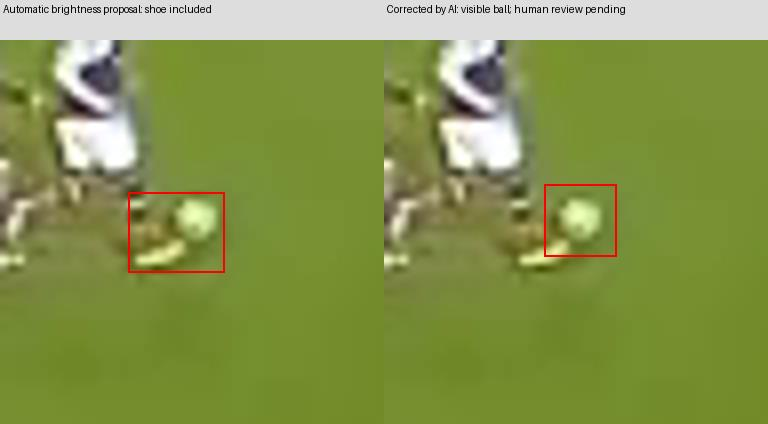

In [10]:
display(Image(filename=str(DOC/'Trainingsbewijs/fouten/assisted-label-correction.jpg'),width=900))

## 8. Historische training opnieuw uitvoeren
De echte scripts staan onder final/scripts en src/football_pipeline. Voor exacte v3-herhaling zijn
de oorspronkelijke `data/broadcast-training-v2` (ball-coco én balls),
`data/broadcast-ball-review-v1/curated` en `artifacts/broadcast-ball-v2/broadcast_ball_v2.pt` nodig.
Deze volledige corpora en v2-startgewichten ontbreken in het compacte apppakket.
De 80 reviewbeelden zijn geen vervangende dataset met dezelfde historische scores.

Vanuit een complete oorspronkelijke projectkopie gebruikt de historische route:
```powershell
$env:PYTHONPATH = 'src;.'
.\.venv\Scripts\python.exe scripts/experiment_broadcast_v3.py --output artifacts/bal-v3-herhaling-nieuw
```
Bewaar een nieuwe outputmap. Controleer eerst fingerprints, CUDA, gewichten en dependencies.
De oorspronkelijke args.yaml bevat absolute machinepaden als herkomstbewijs, niet als universele paden.

## 9. Eventuele nieuwe training op de gereviewde 80 beelden
De volgende cel staat uit. Zij is **nieuwe training**, geen reconstructie van de historische v2/v3-run.
De menselijke review is nu geregistreerd. Bij toekomstige labelcorrecties maakt het team een
nieuwe datasetversie; bij ongewijzigde goedkeuring bewaart het de bestaande labels en reviewregistratie. De cel start alleen na expliciete wijziging
van de schakelaar en ingevulde paden. Zij kiest bewust geen onbevestigd YOLO26-model.

In [11]:
RUN_NEW_TRAINING=False
REVIEWED_MANIFEST=None  # Pad naar een nieuwe, werkelijk gereviewde datasetversie.
DATA_YAML=None          # De bijbehorende train/val-configuratie.
START_WEIGHTS=None      # Expliciet gekozen checkpoint; noteer SHA-256 en libraryversie.
if RUN_NEW_TRAINING:
    assert all(x is not None for x in [REVIEWED_MANIFEST,DATA_YAML,START_WEIGHTS]), 'Vul echte paden in.'
    reviewed=read(REVIEWED_MANIFEST)
    assert reviewed.get('human_review_completed') is True, 'Menselijke review is nog open.'
    output=FINAL/'artifacts/nieuwe-gereviewde-baltraining'
    assert not output.exists(), 'Kies een nieuwe uitvoermap.'
    from ultralytics import YOLO
    model=YOLO(str(START_WEIGHTS))
    model.train(data=str(Path(DATA_YAML).resolve()),epochs=16,imgsz=640,batch=4,
                optimizer='Adam',lr0=0.0001,freeze=0,patience=8,seed=42,
                mosaic=0.0,mixup=0.0,scale=0.0,fliplr=0.5,
                project=str(output.parent),name=output.name,exist_ok=False)
    result=model.val(data=str(Path(DATA_YAML).resolve()),split='val',imgsz=640)
    print('Nieuwe ontwikkelmetrics:',result.box.map50,result.box.map)
else:
    print('Geen training gestart. De 80-labelreview is geregistreerd; concrete trainingskoppeling en ruwe nieuwe experimentbijlagen blijven open.')

Geen training gestart. De 80-labelreview is geregistreerd; concrete trainingskoppeling en ruwe nieuwe experimentbijlagen blijven open.


## 10. Wat het team zelfstandig moet uitleggen
Hoe de eigen labels invloed hebben op kleine-objecttraining, waarom buurframes niet over splits
horen, wat beide AP-maten betekenen, hoe de freezeproef is opgezet en waarom v3 bij tegels hoort.
Daarnaast: minimaal vier veldpunten, grondcontact in plaats van boxcentrum, ongeldige kalibratie,
tijdelijke ID's en de beperkingen van team- en afstandsschattingen.

Lees ook Requirementscontrole.md, GenAI_en_Eigenaarschap.md en YOLO26_Vervolg.md.
Dit notebook en de uitleg zijn met Codex-hulp gemaakt. Er is geen menselijke review nagebootst.

## 11. Nieuwste Git-versie en verschil met final
De pull bracht de gedeelde hoofdbron op **524d081a**. De nieuwe bron bevat ook de geregistreerde
teamreview in final en Jorres technische afronding. De GitHub-final-versie heeft een schoolroute.
De nieuwste bron gebruikt Andrew voor de bal en heeft een herstelbare spelersdrempel.
De gekopieerde handleidingen/configuraties zijn hieronder op hun opgeslagen hash gecontroleerd.
De bronkopie in de ZIP staat onder Nieuwste_bron. In deze workspace staat zij onder Messi10.

In [12]:
version=read(DOC/'Versiebewijs/repository-versie.json')
print('Git-versie:',version['revision'])
print(version['source_scope'])
for row in version['copied_evidence']:
    assert checksum(DOC/'Versiebewijs'/row['path'])==row['sha256']
latest_profile=read(DOC/'Versiebewijs/configs/models-broadcast.json')
display(pd.DataFrame([{'model':m['model_id'],'invoer':m['imgsz'],'confidence':m['confidence'],'klassen':str(m['class_mapping'])} for m in latest_profile['models']]))
latest_root=next((p for p in [base,base/'Nieuwste_bron',base/'Messi10'] if (p/'configs/models-broadcast.json').exists()),None)
if latest_root is not None:
    andrew=(latest_root/'configs'/latest_profile['models'][-1]['weights']).resolve()
    assert checksum(andrew)==latest_profile['models'][-1]['weights_sha256']
    print('Andrew-gewicht gecontroleerd:',andrew.stat().st_size,'bytes')
print('Bewaarde final-modellen:',[m['model_id'] for m in profile['models']])
print('Hoofdbron en GitHub-final hebben verschillende startprocedures. Raadpleeg de README van de gekozen versie.')

model,invoer,confidence,klassen
broadcast-pitch-players-v7,1920,0.10,{'0': 'player'}
coco-person-proposals,1920,0.10,{'0': 'person'}
andrew-ball-v1,1280,0.03,{'0': 'ball'}


Git-versie: 524d081a445dd57762e14eeb1e7142bbb9a3ba53
GitHub main op 524d081a; lokale niet-gepubliceerde appwijzigingen worden niet als GitHub-functies voorgesteld.
Andrew-gewicht gecontroleerd: 136786938 bytes
Bewaarde final-modellen: ['broadcast-pitch-players-v7', 'coco-person-proposals', 'andrew-ball-v1']
Hoofdbron en GitHub-final hebben verschillende startprocedures. Raadpleeg de README van de gekozen versie.


## 12. YOLO26-uitkomst volgens de opgehaalde handleiding
De tabel gebruikt **bronrapportages**, niet de ruwe comparison.json of een nieuwe modelrun.
Die lokale experimentmap is niet meegecommit en ontbreekt hier. De bestaande YOLO11s blijft gekozen.
De scores gebruiken ontwikkelvalidatie, één seed, 348 detectorbeelden en 341 pipelinebeelden.
F1 middelt over drie wedstrijden. Binnen 0,5 procentpunt bepaalt detectorstacktijd de voorkeur.
De tijden bevatten geen decoding, rol/teamclassificatie of veldherkenning en zijn geen video-FPS.
Nieuwe exacte AP-getallen zijn niet uit de bron beschikbaar en worden niet ingevuld.

In [13]:
yolo26_reported=pd.DataFrame(version['yolo26_rows'])
display(yolo26_reported)
display(Markdown('**Bron:** Versiebewijs/docs/Yolo26_Spelersvergelijking.md. Ruwe lokale metingen ontbreken.'))
print('Gerapporteerde keuze: huidig YOLO11s behouden; Andrew alleen voor bal.')
print('Volgens handleiding: YOLO26 stopt epoch 24 (beste 4), YOLO11 epoch 31 (beste 11).')
print('Nieuwe training begon na OOM opnieuw op 1280. Geen nieuwe AP-resultaten hier herberekend.')

model,pipeline_F1_pct,detectorstack_median_ms
Huidig YOLO11s,91.81,250.81
Opnieuw getraind YOLO11s,91.62,251.18
Opnieuw getraind YOLO26s,91.45,252.67


<IPython.core.display.Markdown object>

Gerapporteerde keuze: huidig YOLO11s behouden; Andrew alleen voor bal.
Volgens handleiding: YOLO26 stopt epoch 24 (beste 4), YOLO11 epoch 31 (beste 11).
Nieuwe training begon na OOM opnieuw op 1280. Geen nieuwe AP-resultaten hier herberekend.


## 13. Tracking volgens de opgehaalde handleiding
Ook dit is een bronrapportage; de lokale ruwe auditmap ontbreekt. Drie clips bevatten elk 150
opeenvolgende gelabelde ontwikkelframes met providergeometrie. De totale IDF1 is een gerapporteerde
aggregatie en mag niet worden vervangen door het gemiddelde van de drie percentages.
Deze meting hoort bij de nieuwste hoofdbron en geldt niet automatisch voor de bewaarde final.

In [14]:
display(pd.DataFrame(version['tracking_rows']))
display(pd.DataFrame([version['tracking_aggregate']]))
print('Bron: Versiebewijs/docs/Spelersdrempel_en_tracking.md; ruwe auditmap ontbreekt.')
print('Huidige lokale documentatiecontrole: 75 gerichte regressietests geslaagd; gedeelde CPU-controle meldt 537 + 4 subtests en 1 GPU-skip.')
print('Geen nieuwe volledige echte videorun en geen nieuwe training uitgevoerd.')

clip,frames,IDF1_pct,ID_switches
SNGS-021,150,98.12,0
SNGS-039,150,89.73,8
SNGS-078,150,95.12,1


frames,IDF1_pct,ID_switches
450,93.95,9


Bron: Versiebewijs/docs/Spelersdrempel_en_tracking.md; ruwe auditmap ontbreekt.
Huidige lokale documentatiecontrole: 75 gerichte regressietests geslaagd; gedeelde CPU-controle meldt 537 + 4 subtests en 1 GPU-skip.
Geen nieuwe volledige echte videorun en geen nieuwe training uitgevoerd.


## 14. Andrews model, prototype en AI-verantwoording
De bron is docs/VierKlassenModel.md, met AI-gebruik in hoofdstuk 16, plus het oorspronkelijke
trainingsnotebook. Het model traint vier klassen, het oorspronkelijke deploymentprototype toont
bal en scheidsrechters en de gedeelde broadcastpipeline gebruikt alleen de baluitvoer.
De eigen extrapolatie en greedy matching uit Andrews prototype zijn geen ByteTrack of automatisch
een Kalmanfilter. Zijn AI-verklaring noemt documentstructuur, eerste codeonderdelen en debugging,
met handmatige beoordeling en verantwoordelijkheid bij de auteur. Toolnamen/model-ID's zijn niet ingevuld.


In [15]:
original=read(DOC/'Versiebewijs/Andrew_Prototype/train.ipynb')
for cell in original['cells']:
    source=''.join(cell['source'])
    if cell['cell_type']=='code' and 'model.train(' in source:
        print(source)
review=read(DOC/'Versiebewijs/final/datasets/school-ball80-review-v1/manifest.json')
print('Teamreview:',review['human_review_completed'],len(review['frames']),'beelden')
print('Voorbereiding en labels behouden; registratie is geen nieuwe training.')
shared=read(DOC/'Versiebewijs/reports/release-20261114/checks.json')
display(pd.DataFrame([shared['tests']]))
print('Broncontrole van Jorre; niet als dezelfde run opgeteld bij de lokale 75 tests.')

passed,skipped,subtests_passed,failures,errors,runtime_s,skipped_reason
537,1,4,0,0,79.431,GPU smoke test: no CUDA device in this environment



import torch
from ultralytics import YOLO

#GPU CHECK

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is not available. Check your PyTorch installation.")

print("GPU:", torch.cuda.get_device_name(0))
print("Total GPU memory:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
), "GB")

#LIMIT PYTORCH GPU MEM TO 85%

torch.cuda.set_per_process_memory_fraction(0.85, 0)

print("PyTorch GPU memory limit: 85%")

#TRAINING

model = YOLO("yolov8x.pt")

results = model.train(
    data="archive/data.yaml",
    
    epochs=50,
    imgsz=1280,
    batch=6,

    patience=20,
    workers=2,
    device=0,

    project="soccer_training",
    name="ball_detector_640",

    save=True,
    plots=True,
    amp=True
)

print("\nTraining completed!")

print("Best model saved at:")
print("soccer_training/soccer_yolo/weights/best.pt")

print("Last checkpoint saved at:")
print("soccer_training/soccer_yolo/weights/last.pt")

Teamreview: True 80 beelden
Voorbereiding en 